In [19]:
from utils import add_project_root_to_sys_path
add_project_root_to_sys_path()
from neuralnet import get_logger
from neuralnet.matplotlib import get_color_cycle

import polars as pl
import matplotlib.pyplot as plt
import mplhep as hep
plt.style.use(hep.style.ATLAS)
from math import isinf

In [2]:
def get_rename_function(prefix: str):
    def rename_function(col_name: str) -> str:
        if col_name.startswith(('et_bin', 'eta_bin')):
            return col_name

        return f'{prefix}.{col_name}'
    return rename_function

In [7]:
qat_df = pl.read_parquet('/home/lucasbanunes/data/neuralnet_jobs/sbrt_new/qat_mlp_v1/training/selected_models.parquet').rename(get_rename_function('qat'))
fp_df = pl.read_parquet('/home/lucasbanunes/data/neuralnet_jobs/sbrt_new/mlp_v0/training/selected_models.parquet').rename(get_rename_function('fp'))
history_df = qat_df.join(fp_df, on=['et_bin.low', 'et_bin.high','eta_bin.low', 'eta_bin.high'], how='inner')
history_df.schema

Schema([('et_bin.low', Float64),
        ('et_bin.high', Float64),
        ('et_bin.closed', String),
        ('eta_bin.low', Float64),
        ('eta_bin.high', Float64),
        ('eta_bin.closed', String),
        ('qat.fold', Int64),
        ('qat.id', Int64),
        ('qat.init', Int64),
        ('qat.history.start', Datetime(time_unit='us', time_zone=None)),
        ('qat.history.end', Datetime(time_unit='us', time_zone=None)),
        ('qat.history.train.accuracy', List(Float64)),
        ('qat.history.train.loss', List(Float64)),
        ('qat.history.val.accuracy', List(Float64)),
        ('qat.history.val.loss', List(Float64)),
        ('qat.history.val.max_sp', List(Float64)),
        ('qat.history.val.max_sp_fa', List(Float64)),
        ('qat.history.val.max_sp_pd', List(Float64)),
        ('qat.history.val.max_sp_threshold', List(Float64)),
        ('qat.history.val.max_sp_best_epoch', List(Int64)),
        ('qat.fit.train.accuracy', Float64),
        ('qat.fit.train.loss', 

 [Sun, 20 Sep 2026 15:34:53] INFO et_bin: [15000.0, 20000.0], eta_bin: [1.37, 1.52]


 [Sun, 20 Sep 2026 15:34:53] INFO Substituting symbol \in from Computer Modern
 [Sun, 20 Sep 2026 15:34:53] INFO et_bin: [20000.0, 30000.0], eta_bin: [1.37, 1.52]
 [Sun, 20 Sep 2026 15:34:53] INFO Substituting symbol \in from Computer Modern
 [Sun, 20 Sep 2026 15:34:53] INFO et_bin: [15000.0, 20000.0], eta_bin: [2.37, 2.5]
 [Sun, 20 Sep 2026 15:34:53] INFO Substituting symbol \in from Computer Modern
 [Sun, 20 Sep 2026 15:34:53] INFO et_bin: [30000.0, 40000.0], eta_bin: [1.37, 1.52]
 [Sun, 20 Sep 2026 15:34:53] INFO Substituting symbol \in from Computer Modern
 [Sun, 20 Sep 2026 15:34:53] INFO et_bin: [40000.0, 50000.0], eta_bin: [2.37, 2.5]
 [Sun, 20 Sep 2026 15:34:54] INFO Substituting symbol \in from Computer Modern
 [Sun, 20 Sep 2026 15:34:54] INFO et_bin: [50000.0, inf], eta_bin: [2.37, 2.5]
 [Sun, 20 Sep 2026 15:34:54] INFO Substituting symbol \in from Computer Modern
 [Sun, 20 Sep 2026 15:34:54] INFO et_bin: [50000.0, inf], eta_bin: [0.8, 1.37]
 [Sun, 20 Sep 2026 15:34:54] INFO 

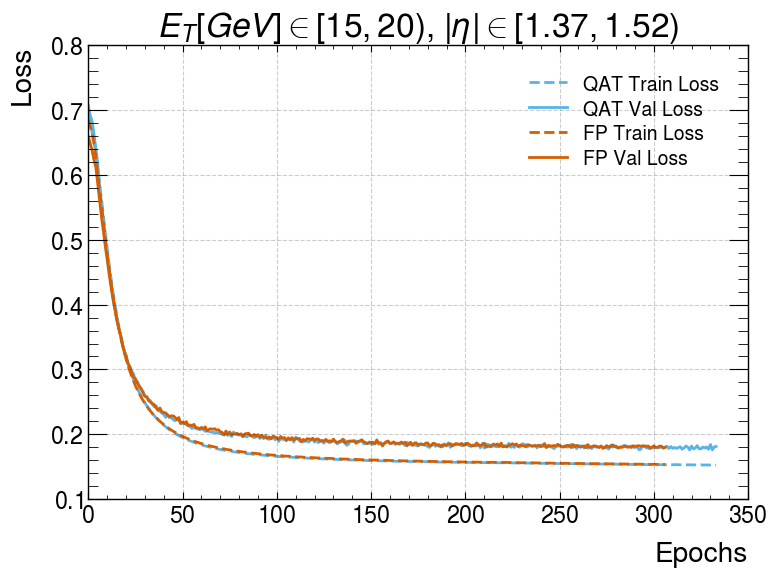

 [Sun, 20 Sep 2026 15:34:59] INFO Substituting symbol \in from Computer Modern


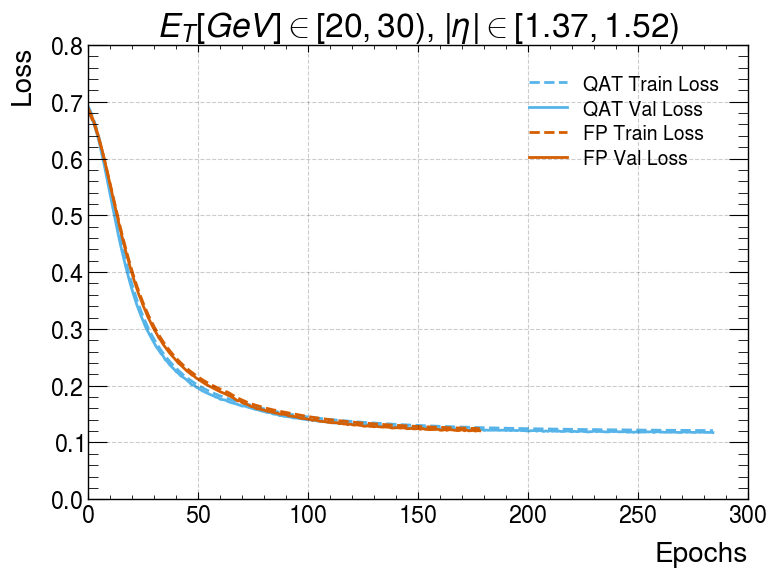

 [Sun, 20 Sep 2026 15:35:00] INFO Substituting symbol \in from Computer Modern


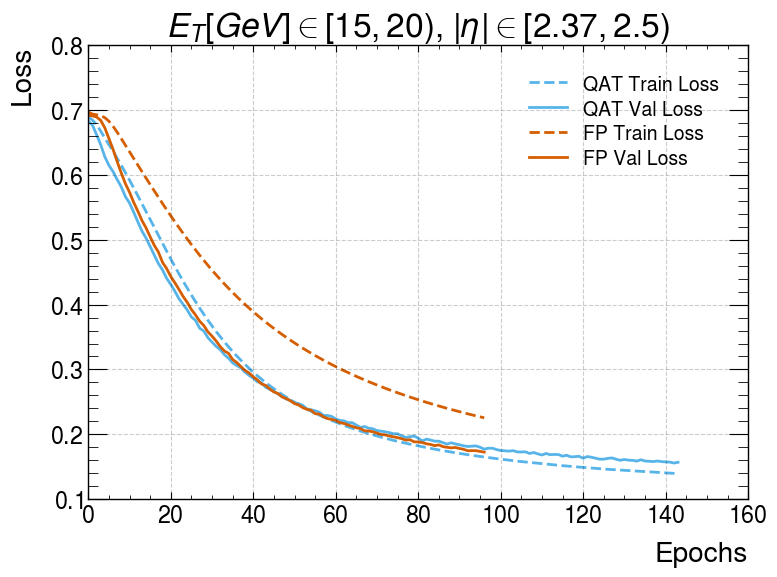

 [Sun, 20 Sep 2026 15:35:00] INFO Substituting symbol \in from Computer Modern


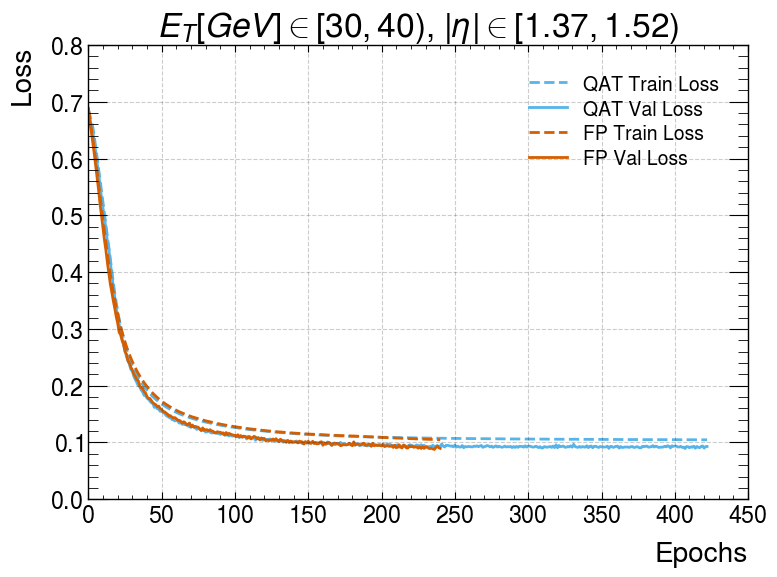

 [Sun, 20 Sep 2026 15:35:00] INFO Substituting symbol \in from Computer Modern


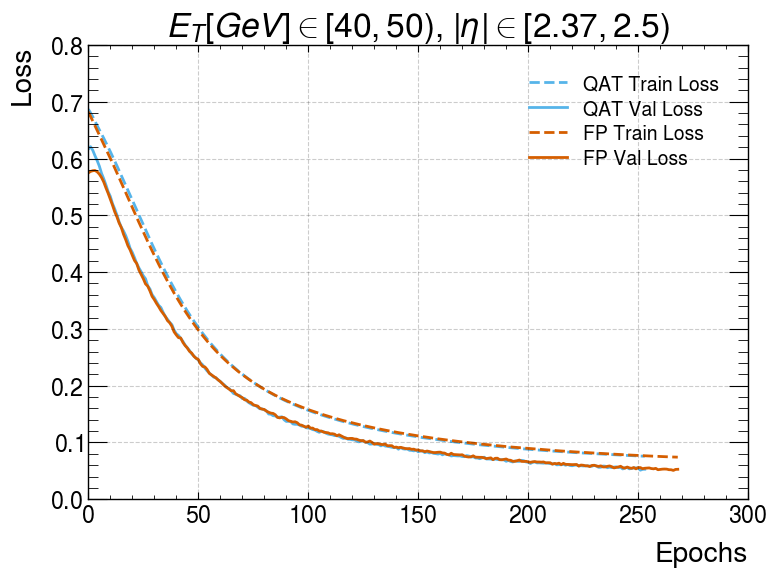

 [Sun, 20 Sep 2026 15:35:01] INFO Substituting symbol \in from Computer Modern


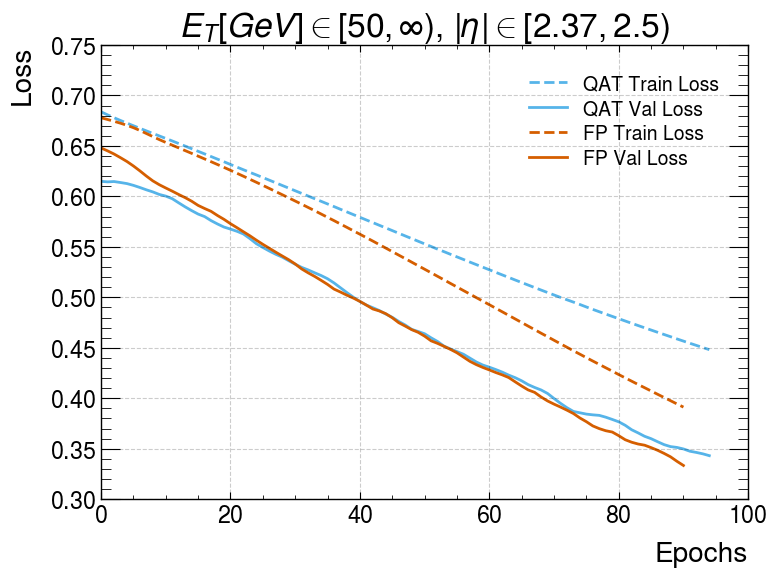

 [Sun, 20 Sep 2026 15:35:01] INFO Substituting symbol \in from Computer Modern


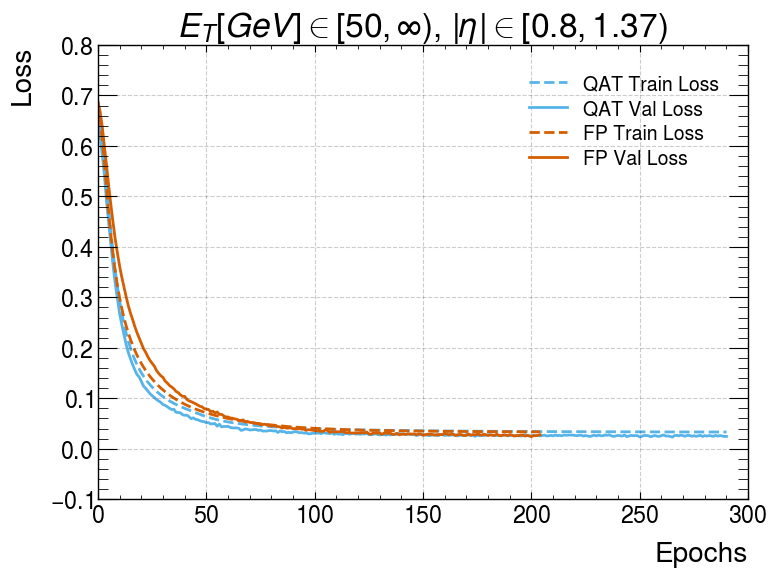

 [Sun, 20 Sep 2026 15:35:01] INFO Substituting symbol \in from Computer Modern


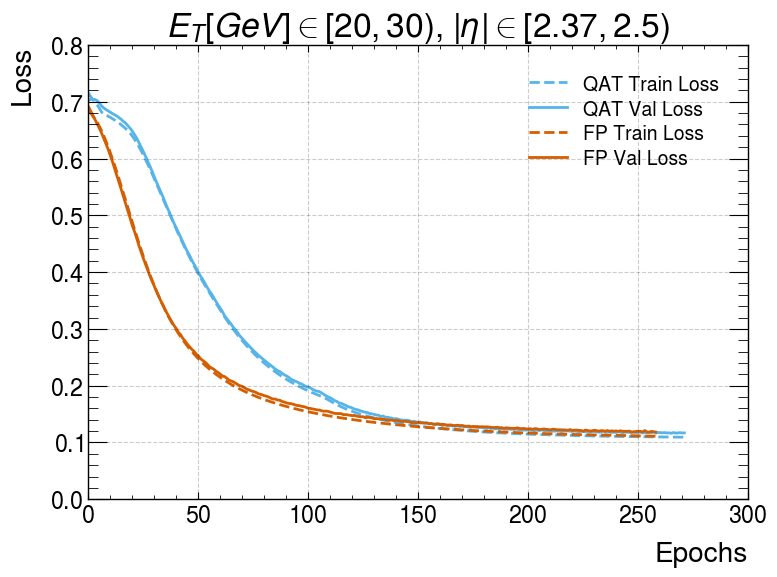

 [Sun, 20 Sep 2026 15:35:01] INFO Substituting symbol \in from Computer Modern


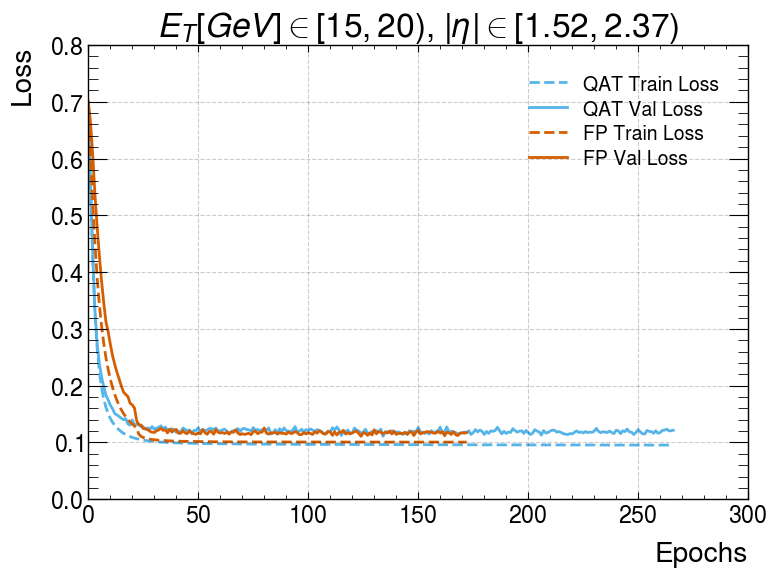

 [Sun, 20 Sep 2026 15:35:01] INFO Substituting symbol \in from Computer Modern


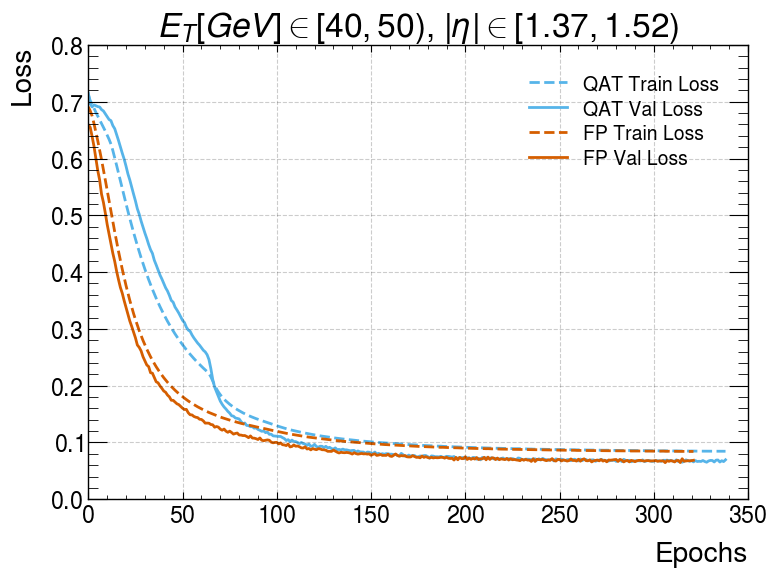

 [Sun, 20 Sep 2026 15:35:02] INFO Substituting symbol \in from Computer Modern


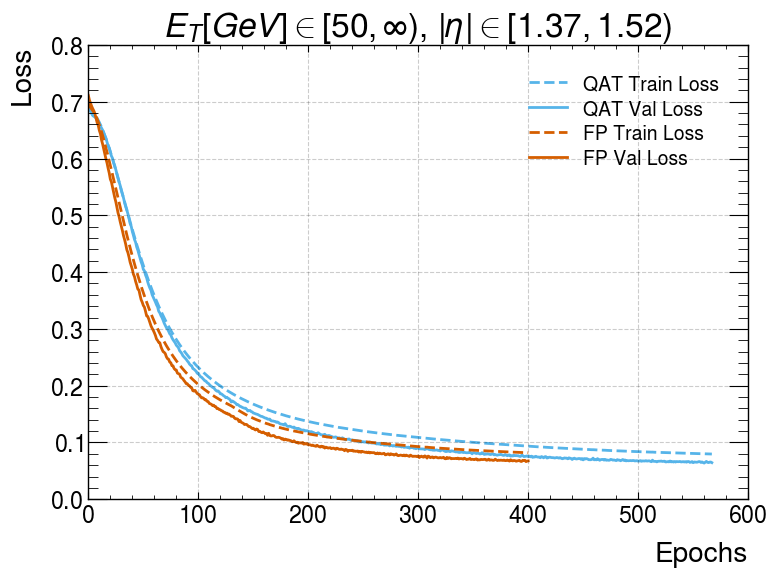

 [Sun, 20 Sep 2026 15:35:02] INFO Substituting symbol \in from Computer Modern


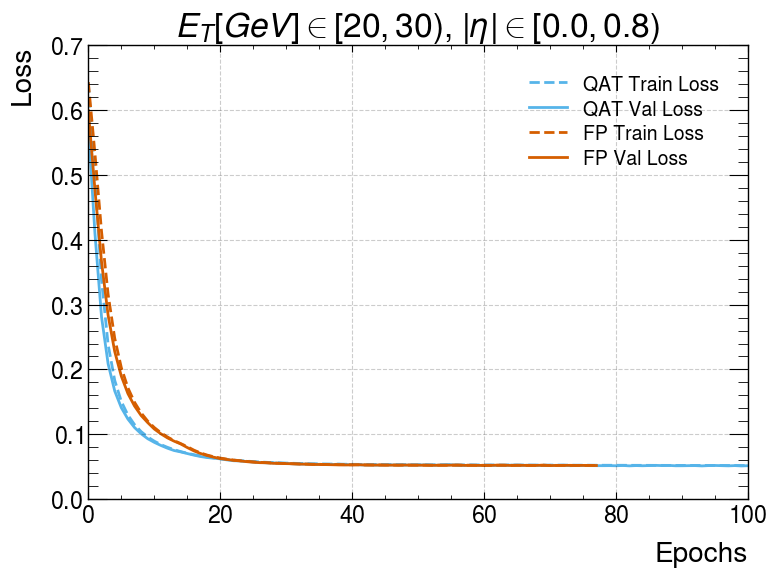

 [Sun, 20 Sep 2026 15:35:02] INFO Substituting symbol \in from Computer Modern


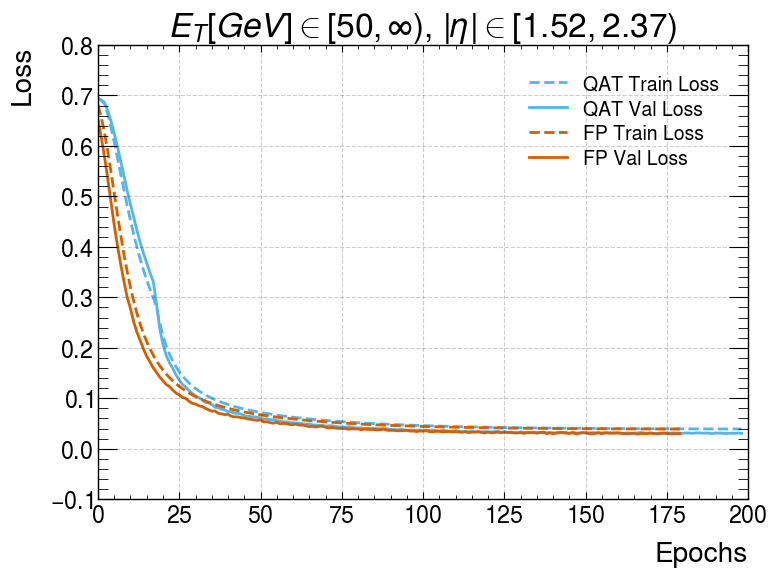

 [Sun, 20 Sep 2026 15:35:02] INFO Substituting symbol \in from Computer Modern


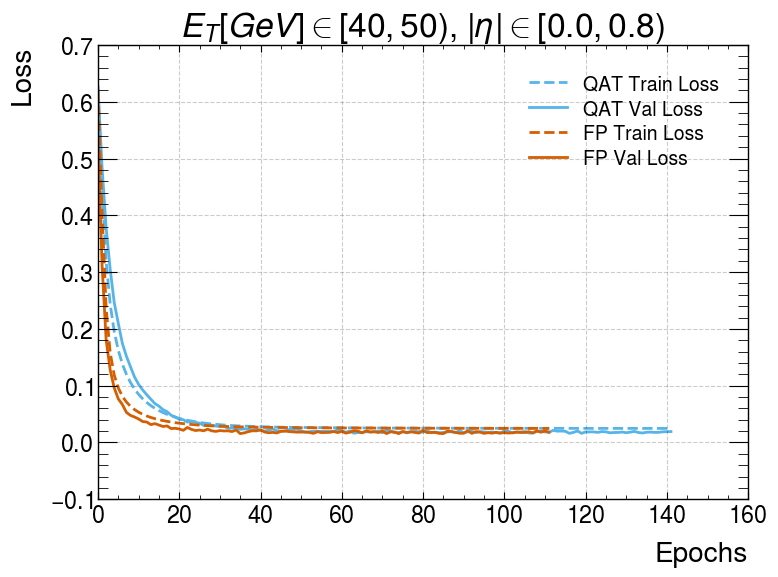

 [Sun, 20 Sep 2026 15:35:03] INFO Substituting symbol \in from Computer Modern


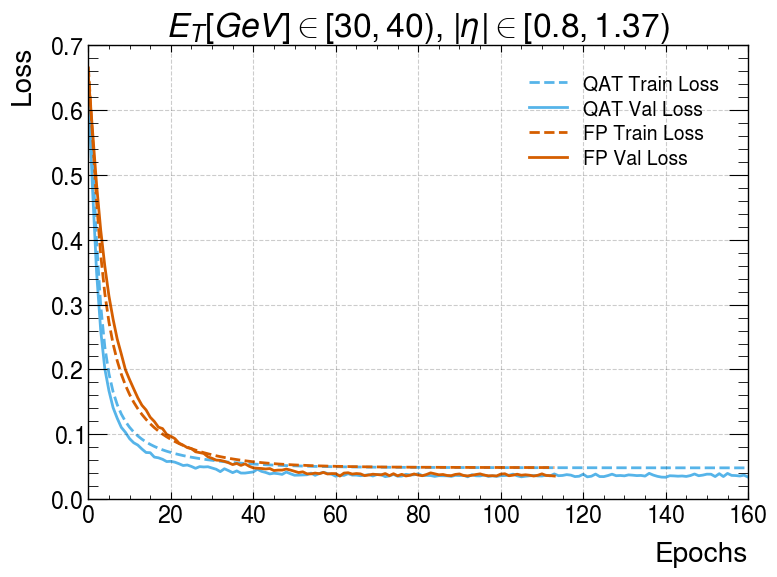

 [Sun, 20 Sep 2026 15:35:03] INFO Substituting symbol \in from Computer Modern


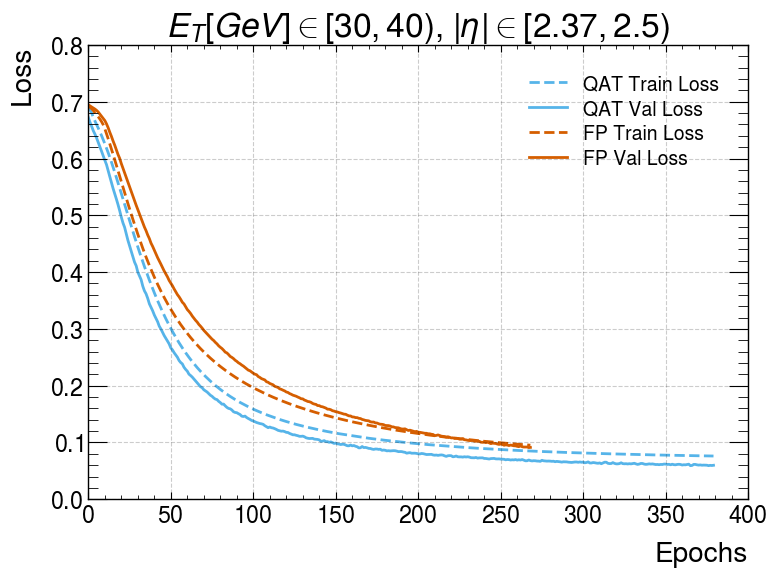

 [Sun, 20 Sep 2026 15:35:03] INFO Substituting symbol \in from Computer Modern


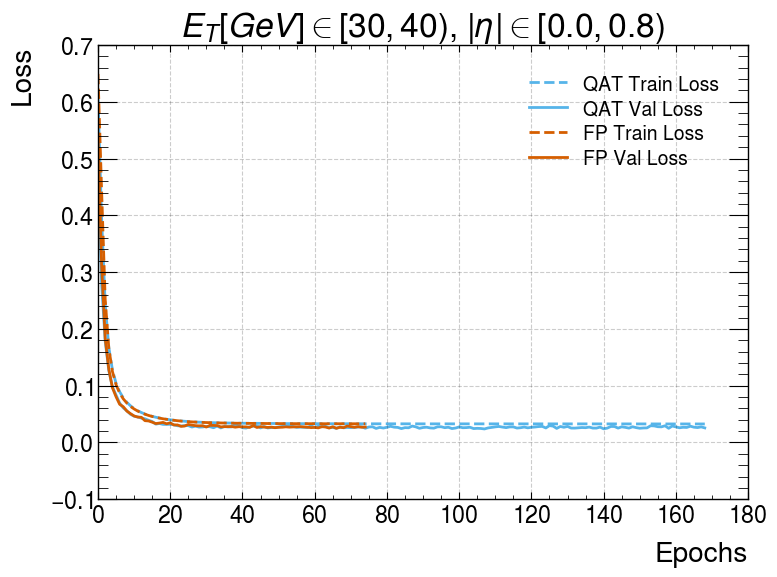

 [Sun, 20 Sep 2026 15:35:04] INFO Substituting symbol \in from Computer Modern


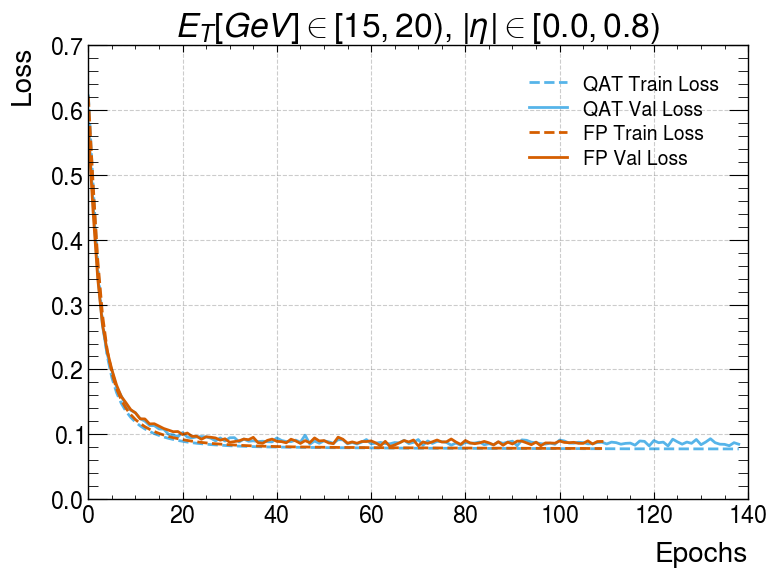

 [Sun, 20 Sep 2026 15:35:04] INFO Substituting symbol \in from Computer Modern


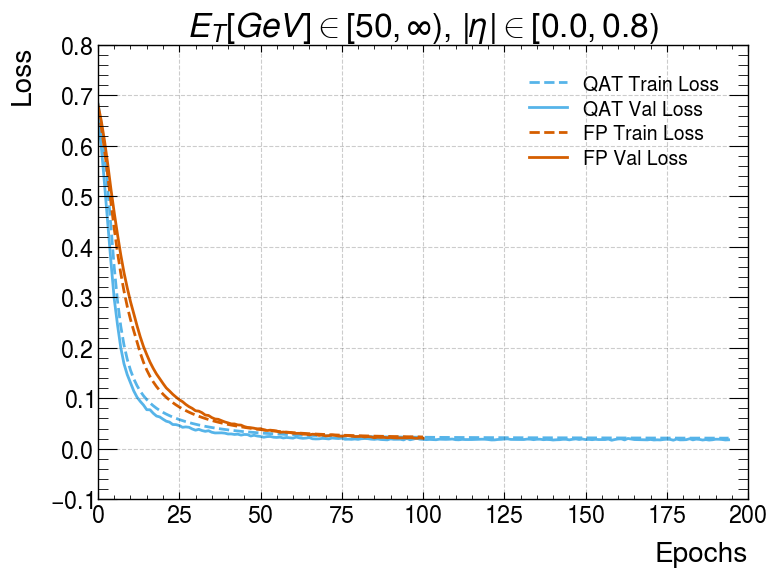

 [Sun, 20 Sep 2026 15:35:04] INFO Substituting symbol \in from Computer Modern


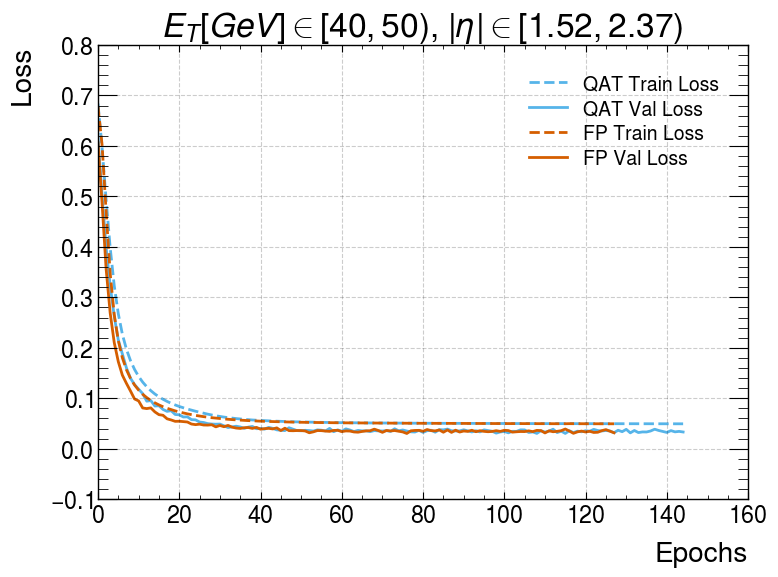

 [Sun, 20 Sep 2026 15:35:04] INFO Substituting symbol \in from Computer Modern


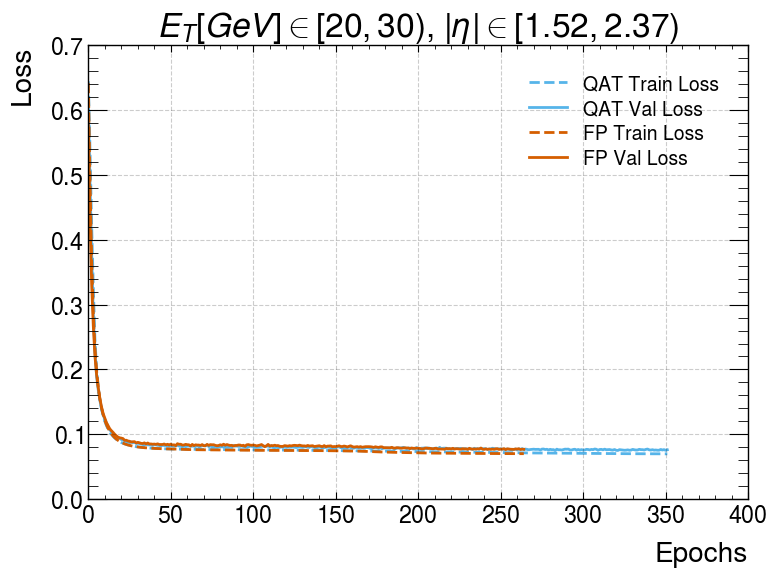

 [Sun, 20 Sep 2026 15:35:05] INFO Substituting symbol \in from Computer Modern


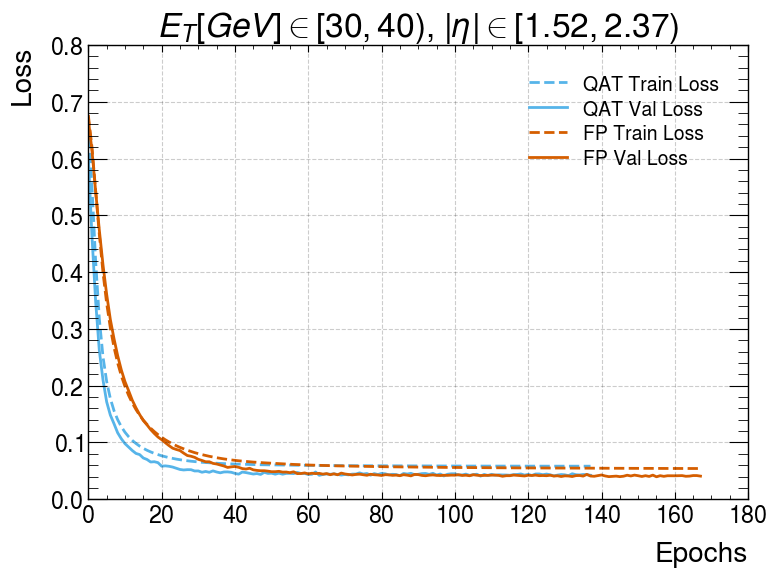

 [Sun, 20 Sep 2026 15:35:05] INFO Substituting symbol \in from Computer Modern


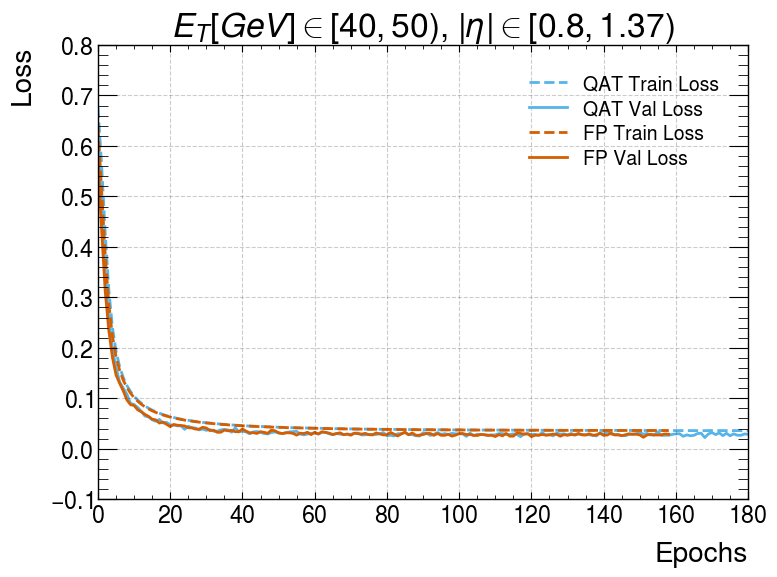

 [Sun, 20 Sep 2026 15:35:05] INFO Substituting symbol \in from Computer Modern


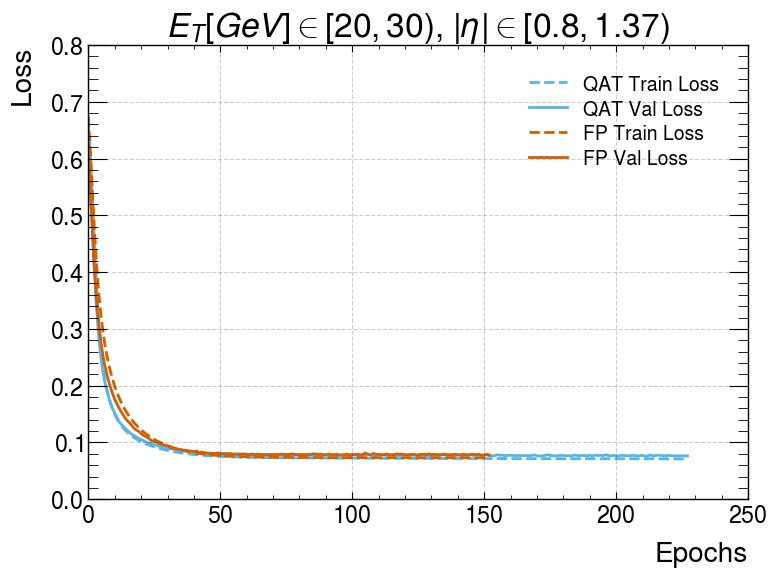

 [Sun, 20 Sep 2026 15:35:06] INFO Substituting symbol \in from Computer Modern


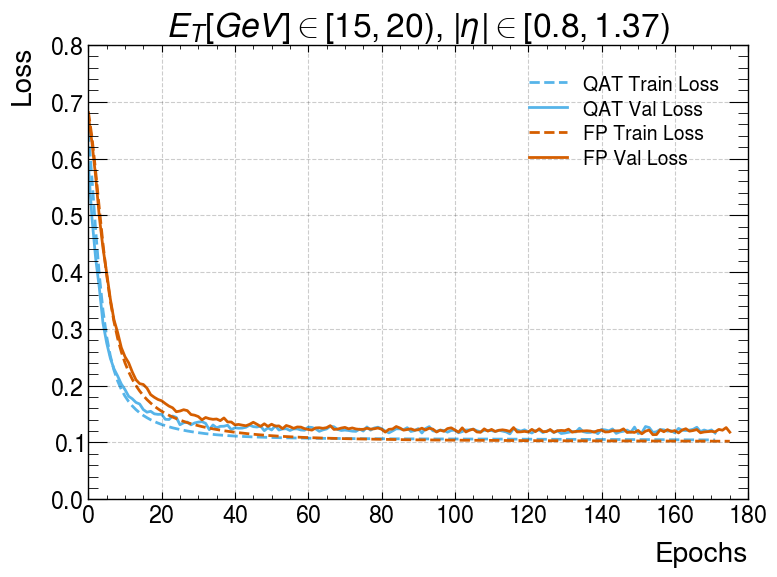

In [21]:
color_cycle = get_color_cycle()
to_plot = [
    {
        'col': 'qat.history.train.loss',
        'label': 'QAT Train Loss',
        'color': color_cycle[1],
        'style': '--',
    },
    {
        'col': 'qat.history.val.loss',
        'label': 'QAT Val Loss',
        'color': color_cycle[1],
        'style': '-',
    },
    {
        'col': 'fp.history.train.loss',
        'label': 'FP Train Loss',
        'color': color_cycle[0],
        'style': '--',
    },
    {
        'col': 'fp.history.val.loss',
        'label': 'FP Val Loss',
        'color': color_cycle[0],
        'style': '-',
    }
]
logger = get_logger()
for row in history_df.iter_rows(named=True):
    logger.info(f"et_bin: [{row['et_bin.low']}, {row['et_bin.high']}], eta_bin: [{row['eta_bin.low']}, {row['eta_bin.high']}]")
    fig, ax = plt.subplots()
    ax.grid(linestyle="--", alpha=0.2, color="k")
    if isinf(row['et_bin.high']):
        et_bin_high_label = '\\infty'
    else:
        et_bin_high_label = str(round(float(row['et_bin.high'])*1e-3))
    for plot_config in to_plot:
        col = plot_config['col']
        label = plot_config['label']
        color = plot_config['color']
        style = plot_config['style']
        ax.plot(row[col], label=label, color=color, linestyle=style)
    ax.set_xlabel('Epochs')
    ax.set_ylabel('Loss')
    ax.set_title(f"$E_T[GeV] \\in [{round(row['et_bin.low']*1e-3)}, {et_bin_high_label})$, $|\\eta| \\in [{row['eta_bin.low']}, {row['eta_bin.high']})$")
    ax.legend()
    fig.tight_layout()